1: Tải dữ liệu trực tiếp từ Kaggle

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

# Tự động tìm thư mục gốc dự án
cwd = Path.cwd().resolve()
PROJECT_DIR = next(
    (p for p in [cwd, *cwd.parents] if (p / "data" / "raw").is_dir()),
    cwd,
)
csv_path = PROJECT_DIR / "data" / "raw" / "combined_data.csv"
print("Đường dẫn dữ liệu:", csv_path)

# Đọc file CSV cục bộ
df = pd.read_csv(csv_path)

# Thiết lập style cho biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

Đường dẫn dữ liệu: D:\spam-email-classifier\data\raw\combined_data.csv


2: Kiểm tra tổng quan, dữ liệu thiếu và trùng lặp

In [2]:
print(f"Kích thước dữ liệu: {df.shape[0]:,} dòng, {df.shape[1]} cột")
print("\nThông tin kiểu dữ liệu:")
print(df.info())

print("\n5 dòng đầu tiên:")
display(df.head())

print("\nSố lượng giá trị thiếu (Missing values):")
print(df.isnull().sum())

print(f"\nSố dòng trùng lặp hoàn toàn: {df.duplicated().sum():,}")
print(f"Số nội dung email (text) trùng lặp: {df['text'].duplicated().sum():,}")

# Kiểm tra các email bị rỗng hoặc chỉ chứa khoảng trắng
empty_texts = df['text'].astype(str).str.strip().eq('').sum()
print(f"Số email rỗng/chỉ có khoảng trắng: {empty_texts}")

Kích thước dữ liệu: 83,448 dòng, 2 cột

Thông tin kiểu dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 83448 entries, 0 to 83447
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   83448 non-null  int64
 1   text    83448 non-null  str  
dtypes: int64(1), str(1)
memory usage: 1.3 MB
None

5 dòng đầu tiên:

Số lượng giá trị thiếu (Missing values):
label    0
text     0
dtype: int64

Số dòng trùng lặp hoàn toàn: 0
Số nội dung email (text) trùng lặp: 2
Số email rỗng/chỉ có khoảng trắng: 0


   label                                               text
0      1  ounce feather bowl hummingbird opec moment ala...
1      1  wulvob get your medircations online qnb ikud v...
2      0   computer connection from cnn com wednesday es...
3      1  university degree obtain a prosperous future m...
4      0  thanks for all your answers guys i know i shou...

3: Phân tích phân phối nhãn (Spam vs. Ham)

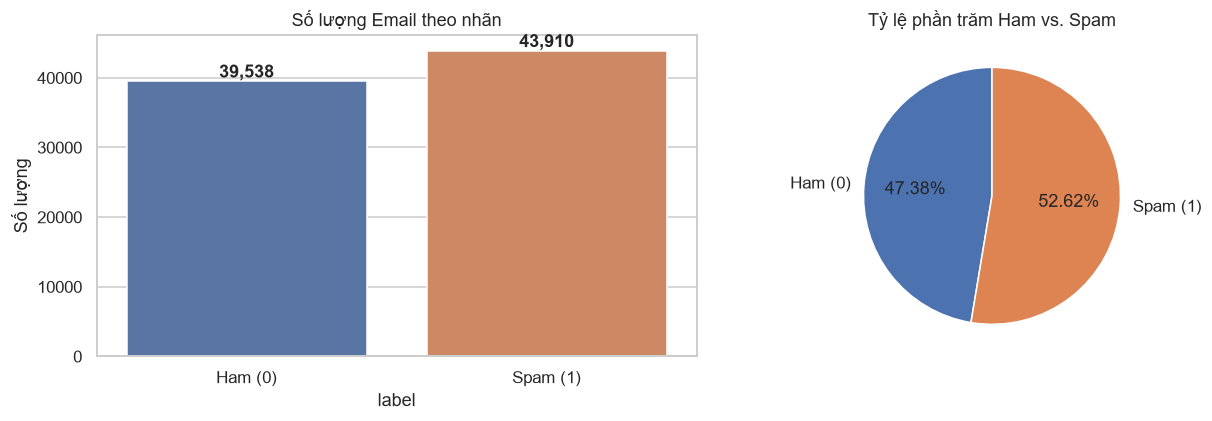

In [3]:
label_counts = df['label'].value_counts()
label_pct = df['label'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Biểu đồ cột
sns.countplot(x='label', data=df, hue='label', palette=['#4C72B0', '#DD8452'], legend=False, ax=axes[0])
axes[0].set_title('Số lượng Email theo nhãn')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Ham (0)', 'Spam (1)'])
axes[0].set_ylabel('Số lượng')
for i, v in enumerate(label_counts.sort_index()):
    axes[0].text(i, v + 500, f"{v:,}", ha='center', fontweight='bold')

# Biểu đồ tròn
axes[1].pie(label_counts.sort_index(), labels=['Ham (0)', 'Spam (1)'],
            autopct='%1.2f%%', startangle=90, colors=['#4C72B0', '#DD8452'])
axes[1].set_title('Tỷ lệ phần trăm Ham vs. Spam')

plt.tight_layout()
plt.show()

4: Phân tích độ dài văn bản (Số ký tự & Số từ)

Thống kê số từ theo từng nhãn:


eda.ipynb#cell-7:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.


      char_count                       ...                               
           count    mean     std  min  ...    25%    50%    75%       max
label                                  ...                               
0        39538.0  2121.7  5666.1  1.0  ...  106.0  200.0  378.0  101984.0
1        43910.0  1249.9  1978.6  1.0  ...   61.0  122.0  249.0   25393.0

[2 rows x 16 columns]

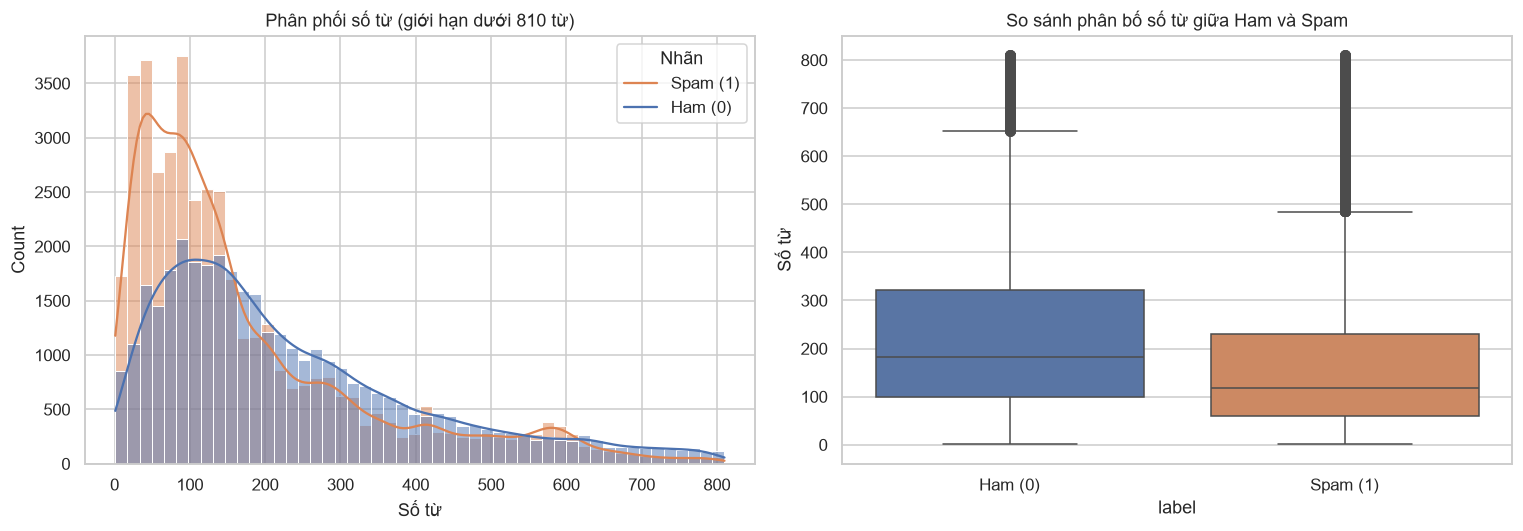

In [4]:
# Tạo đặc trưng độ dài
df['text'] = df['text'].astype(str)
df['char_count'] = df['text'].apply(len)
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

print("Thống kê số từ theo từng nhãn:")
display(df.groupby('label')[['char_count', 'word_count']].describe().round(1))

# Lọc ngưỡng phân vị 95% để vẽ biểu đồ không bị kéo giãn bởi outliers
p95_words = df['word_count'].quantile(0.95)
df_plot = df[df['word_count'] <= p95_words]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram phân phối số từ
sns.histplot(data=df_plot, x='word_count', hue='label', bins=50, kde=True,
             palette=['#4C72B0', '#DD8452'], ax=axes[0])
axes[0].set_title(f'Phân phối số từ (giới hạn dưới {int(p95_words)} từ)')
axes[0].set_xlabel('Số từ')
axes[0].legend(title='Nhãn', labels=['Spam (1)', 'Ham (0)'])

# Boxplot so sánh
sns.boxplot(x='label', y='word_count', data=df_plot, hue='label',
            palette=['#4C72B0', '#DD8452'], legend=False, ax=axes[1])
axes[1].set_title('So sánh phân bố số từ giữa Ham và Spam')
axes[1].set_xticklabels(['Ham (0)', 'Spam (1)'])
axes[1].set_ylabel('Số từ')

plt.tight_layout()
plt.show()

5: Phân tích từ khóa phổ biến (Top Unigrams & Bigrams)

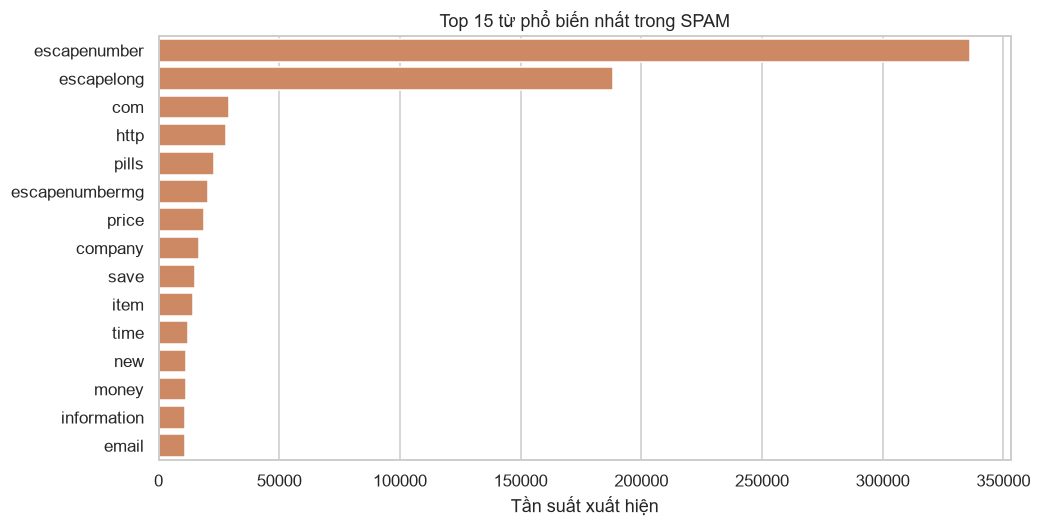

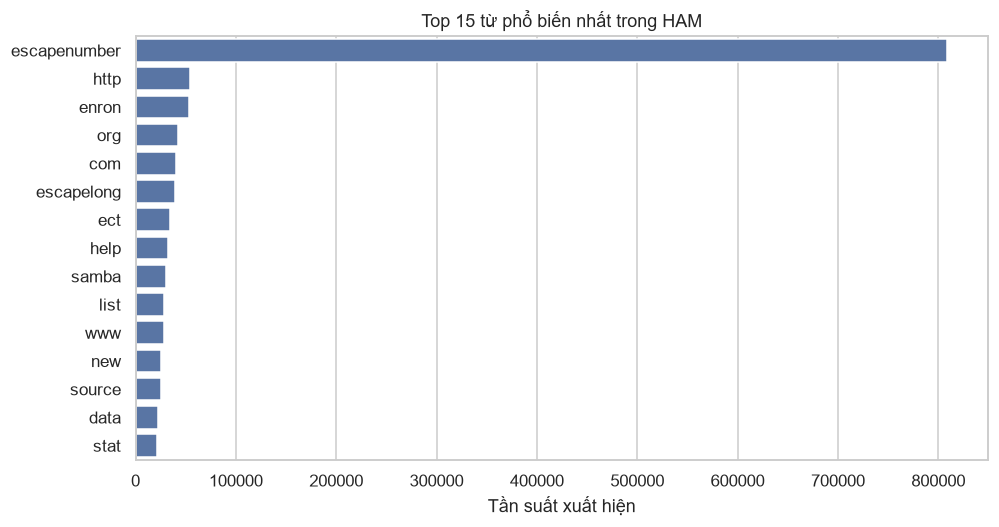

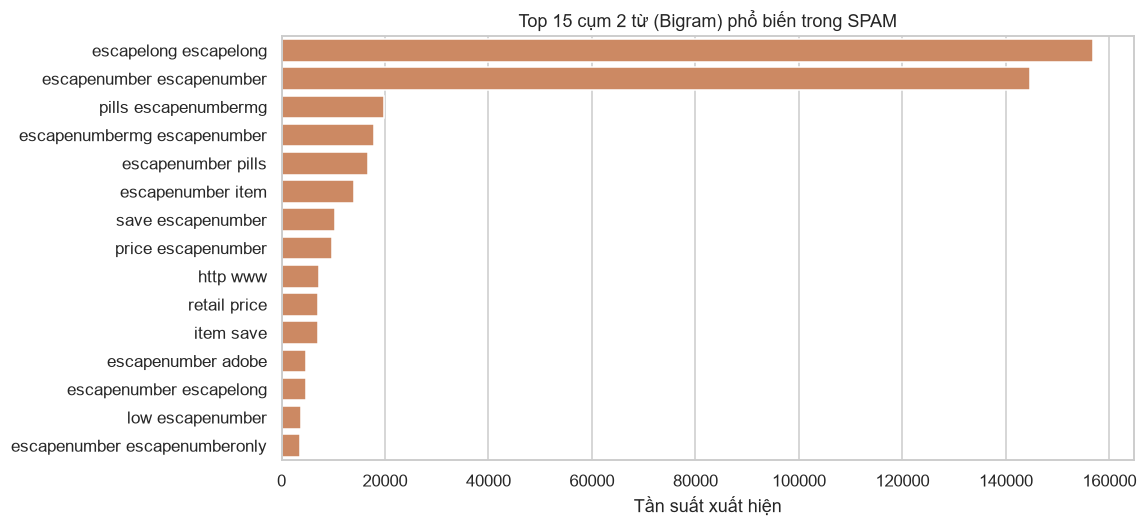

In [5]:
def plot_top_ngrams(corpus, title, ngram_range=(1, 1), top_n=15, color='#4C72B0'):
    vec = CountVectorizer(stop_words='english', ngram_range=ngram_range, max_features=5000)
    bag_of_words = vec.fit_transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)[:top_n]

    words, freqs = zip(*words_freq)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=list(freqs), y=list(words), color=color)
    plt.title(title)
    plt.xlabel('Tần suất xuất hiện')
    plt.show()

spam_texts = df[df['label'] == 1]['text']
ham_texts = df[df['label'] == 0]['text']

# Top 15 từ đơn (Unigrams)
plot_top_ngrams(spam_texts, 'Top 15 từ phổ biến nhất trong SPAM', ngram_range=(1, 1), color='#DD8452')
plot_top_ngrams(ham_texts, 'Top 15 từ phổ biến nhất trong HAM', ngram_range=(1, 1), color='#4C72B0')

# Top 15 cụm 2 từ (Bigrams) - rất hữu ích cho báo cáo
plot_top_ngrams(spam_texts, 'Top 15 cụm 2 từ (Bigram) phổ biến trong SPAM', ngram_range=(2, 2), color='#DD8452')